In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from torchvision.utils import make_grid

import math

In [2]:
SEED = 285
IMAGE_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 2e-4
TIMESTEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02
EVAL_FRACTION = 0.20
EVAL_BATCH_SIZE = 32

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data")

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_root = DATA_DIR
if not dataset_root.is_dir():
    raise FileNotFoundError(f"Dataset path doesn't exist: {dataset_root}")

if dataset_root.name.casefold() == "histopathology":
    histology_root = dataset_root
else:
    matches = sorted(
        folder for folder in dataset_root.rglob("*")
        if folder.is_dir() and folder.name.casefold() == "histopathology"
    )
    if len(matches) != 1:
        raise ValueError(
            f"A Histopathology path is needed, while only {len(matches)} are found: "
            f"{matches}. Please set path to be the real Histopathology path."
        )
    histology_root = matches[0]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
image_paths = sorted(
    file for file in histology_root.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
)
if len(image_paths) < 10:
    raise ValueError(f"There aren't enough images in {len(image_paths)}, please check {histology_root}")

image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, antialias=True),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,) * 3, std=(0.5,) * 3),
])

class HistopathologyDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB"))


dataset = HistopathologyDataset(image_paths, image_transform)
eval_count = round(len(dataset) * EVAL_FRACTION)
train_set, eval_set = random_split(
    dataset,
    [len(dataset) - eval_count, eval_count],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=device.type == "cuda",
)
eval_loader = DataLoader(
    eval_set, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=0,
)

print(f"Device: {device}")
print(f"Histopathology directory: {histology_root}")
print(f"Images: {len(dataset)} | Train: {len(train_set)} | Eval: {len(eval_set)}")

Device: cuda
Histopathology directory: data\Histopathology
Images: 5179 | Train: 4143 | Eval: 1036


In [3]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        half_dim = dim // 2
        frequencies = torch.exp(
            -math.log(10_000) * torch.arange(half_dim) / (half_dim - 1)
        )
        self.register_buffer("frequencies", frequencies)

    def forward(self, timesteps):
        angles = timesteps[:, None].float() * self.frequencies[None, :]
        return torch.cat((angles.sin(), angles.cos()), dim=1)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.skip = (
            nn.Identity() if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_embedding):
        h = self.norm1(self.conv1(x))
        h = h + self.time_projection(time_embedding)[:, :, None, None]
        h = F.silu(h)
        h = self.norm2(self.conv2(h))
        return F.silu(h + self.skip(x))


class DenoisingUNet(nn.Module):
    def __init__(self):
        super().__init__()
        time_dim = 128
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(64),
            nn.Linear(64, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.input_conv = nn.Conv2d(3, 32, 3, padding=1)
        self.encoder1 = ResidualBlock(32, 32, time_dim)
        self.down1 = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.encoder2 = ResidualBlock(64, 64, time_dim)
        self.down2 = nn.Conv2d(64, 128, 4, stride=2, padding=1)

        self.middle1 = ResidualBlock(128, 128, time_dim)
        self.middle2 = ResidualBlock(128, 128, time_dim)

        self.up2 = nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1)
        self.decoder2 = ResidualBlock(128, 64, time_dim)
        self.up1 = nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1)
        self.decoder1 = ResidualBlock(64, 32, time_dim)
        self.output_conv = nn.Conv2d(32, 3, 3, padding=1)
        self.encoder1_extra = ResidualBlock(32, 32, time_dim)
        self.encoder2_extra = ResidualBlock(64, 64, time_dim)
        self.decoder2_extra = ResidualBlock(64, 64, time_dim)
        self.decoder1_extra = ResidualBlock(32, 32, time_dim)

    def forward(self, x, timesteps):
        time_embedding = self.time_mlp(timesteps)

        skip1 = self.encoder1(self.input_conv(x), time_embedding)
        skip1 = self.encoder1_extra(skip1, time_embedding)
        skip2 = self.encoder2(self.down1(skip1), time_embedding)
        skip2 = self.encoder2_extra(skip2, time_embedding)

        h = self.middle1(self.down2(skip2), time_embedding)
        h = self.middle2(h, time_embedding)

        h = self.decoder2(torch.cat((self.up2(h), skip2), dim=1), time_embedding)
        h = self.decoder2_extra(h, time_embedding)
        h = self.decoder1(torch.cat((self.up1(h), skip1), dim=1), time_embedding)
        h = self.decoder1_extra(h, time_embedding)
        return self.output_conv(h)


class DenoisingDiffusionModel(nn.Module):
    def __init__(self, denoiser, timesteps, beta_start, beta_end):
        super().__init__()
        self.denoiser = denoiser
        self.timesteps = timesteps

        betas = torch.linspace(beta_start, beta_end, timesteps)
        alphas = 1.0 - betas
        alpha_bars = torch.cumprod(alphas, dim=0)
        previous_alpha_bars = torch.cat((torch.ones(1), alpha_bars[:-1]))
        posterior_variance = (
            betas * (1.0 - previous_alpha_bars) / (1.0 - alpha_bars)
        )

        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("alpha_bars", alpha_bars)
        self.register_buffer("posterior_std", posterior_variance.sqrt())

    def training_loss(self, clean_images):
        steps = torch.randint(
            self.timesteps, (clean_images.size(0),), device=clean_images.device
        )
        noise = torch.randn_like(clean_images)
        alpha_bar = self.alpha_bars[steps].view(-1, 1, 1, 1)
        signal = alpha_bar.sqrt()
        noise_scale = (1.0 - alpha_bar).sqrt()
        noisy_images = signal * clean_images + noise_scale * noise
        target_v = signal * noise - noise_scale * clean_images
        predicted_v = self.denoiser(noisy_images, steps)
        return F.mse_loss(predicted_v, target_v)

    @torch.inference_mode()
    def sample(self, count, image_size, generator):
        device = self.betas.device
        images = torch.randn(
            count, 3, image_size, image_size, device=device, generator=generator
        )

        for step in reversed(range(self.timesteps)):
            steps = torch.full((count,), step, device=device, dtype=torch.long)
            prediction = self.denoiser(images, steps)
            alpha_bar = self.alpha_bars[step]
            signal = alpha_bar.sqrt()
            noise_scale = (1.0 - alpha_bar).sqrt()

            estimated_clean = signal * images - noise_scale * prediction
            estimated_clean = estimated_clean.clamp(-1.0, 1.0)

            if step == 0:
                return (estimated_clean + 1.0) / 2.0

            previous_alpha_bar = self.alpha_bars[step - 1]
            x0_weight = self.betas[step] * previous_alpha_bar.sqrt() / (1.0 - alpha_bar)
            xt_weight = (
                self.alphas[step].sqrt() * (1.0 - previous_alpha_bar)
                / (1.0 - alpha_bar)
            )
            mean = x0_weight * estimated_clean + xt_weight * images
            noise = torch.randn(
                images.shape, device=device, dtype=images.dtype, generator=generator
            )
            images = mean + self.posterior_std[step] * noise


torch.manual_seed(SEED)
model = DenoisingDiffusionModel(DenoisingUNet(), TIMESTEPS, BETA_START, BETA_END).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

Trainable parameters: 1,455,843


Epoch 001/050 | v MSE: 0.26957 | Checkpoint saved
Epoch 002/050 | v MSE: 0.15349 | Checkpoint saved
Epoch 003/050 | v MSE: 0.13653 | Checkpoint saved
Epoch 004/050 | v MSE: 0.13205 | Checkpoint saved
Epoch 005/050 | v MSE: 0.12394 | Checkpoint saved
Epoch 006/050 | v MSE: 0.12065 | Checkpoint saved
Epoch 007/050 | v MSE: 0.12015 | Checkpoint saved
Epoch 008/050 | v MSE: 0.11919 | Checkpoint saved
Epoch 009/050 | v MSE: 0.11510 | Checkpoint saved
Epoch 010/050 | v MSE: 0.11632 | Checkpoint saved
Epoch 011/050 | v MSE: 0.11364 | Checkpoint saved
Epoch 012/050 | v MSE: 0.11513 | Checkpoint saved
Epoch 013/050 | v MSE: 0.10981 | Checkpoint saved
Epoch 014/050 | v MSE: 0.11123 | Checkpoint saved
Epoch 015/050 | v MSE: 0.11285 | Checkpoint saved
Epoch 016/050 | v MSE: 0.11348 | Checkpoint saved
Epoch 017/050 | v MSE: 0.10940 | Checkpoint saved
Epoch 018/050 | v MSE: 0.10793 | Checkpoint saved
Epoch 019/050 | v MSE: 0.10861 | Checkpoint saved
Epoch 020/050 | v MSE: 0.10576 | Checkpoint saved


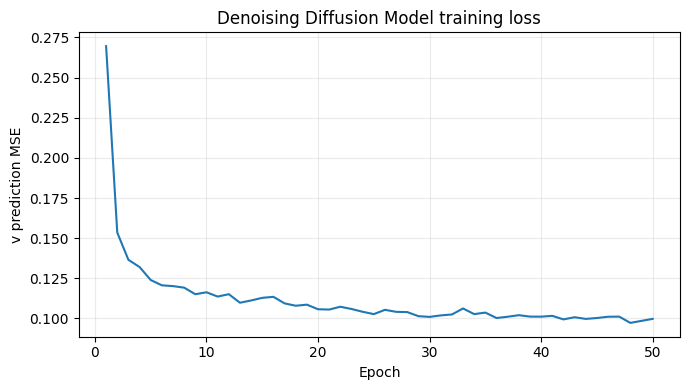

In [4]:
CHECKPOINT_PATH = Path("denoising_diffusion_checkpoint.pt")

def save_checkpoint(completed_epoch, losses):
    checkpoint = {
        "prediction_type": "v",
        "architecture": "deeper_unet",
        "completed_epoch": completed_epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "epoch_losses": list(losses),
    }

    temp_path = CHECKPOINT_PATH.with_suffix(".pt.tmp")
    torch.save(checkpoint, temp_path)
    temp_path.replace(CHECKPOINT_PATH)


start_epoch = 1
epoch_losses = []

if CHECKPOINT_PATH.is_file():
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )
    if checkpoint.get("prediction_type") != "v" or checkpoint.get("architecture") != "deeper_unet":
        raise ValueError(f"{CHECKPOINT_PATH} is incompatible with this model.")
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])

    completed_epoch = checkpoint["completed_epoch"]
    epoch_losses = checkpoint["epoch_losses"]
    start_epoch = completed_epoch + 1
    print(f"Checkpoint loaded, epochs: {completed_epoch}")

if start_epoch > EPOCHS:
    print(f"Already trained {EPOCHS} epochs. No more training needed.")

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    seen_images = 0

    for clean_images in train_loader:
        clean_images = clean_images.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        loss = model.training_loss(clean_images)
        loss.backward()
        optimizer.step()

        batch_size = clean_images.size(0)
        total_loss += loss.item() * batch_size
        seen_images += batch_size

    mean_loss = total_loss / seen_images
    epoch_losses.append(mean_loss)
    save_checkpoint(epoch, epoch_losses)

    print(
        f"Epoch {epoch:03d}/{EPOCHS:03d} | "
        f"v MSE: {mean_loss:.5f} | Checkpoint saved",
        flush=True,
    )


plt.figure(figsize=(7, 4))
plt.plot(range(1, len(epoch_losses) + 1), epoch_losses)
plt.xlabel("Epoch")
plt.ylabel("v prediction MSE")
plt.title("Denoising Diffusion Model training loss")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.gcf().savefig(OUTPUT_DIR / "training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

Held-out real images: mean RGB=(0.751, 0.581, 0.696), near-white area=12.0%
Denoising Diffusion Model: mean RGB=(0.750, 0.641, 0.779), near-white area=2.0%
Saved 16 images and 1 overview to D:\UCSD\ECE 285\assignment3\outputs


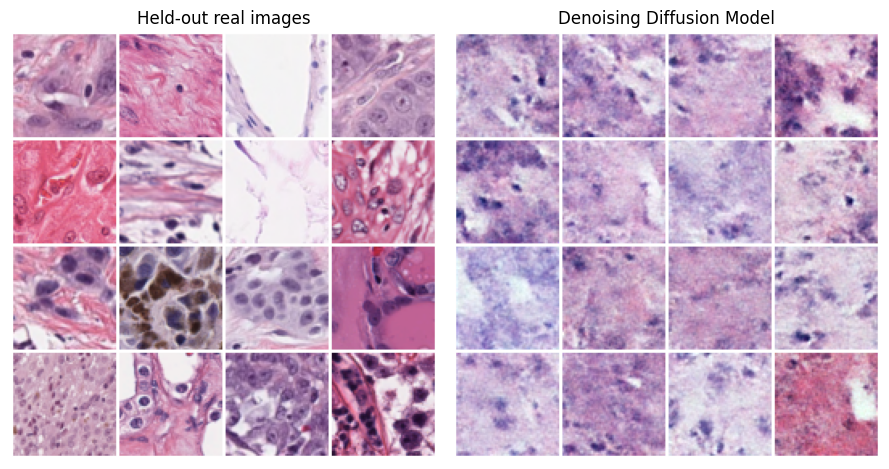

In [5]:
SAMPLE_SEED = 285
SAMPLE_COUNT = 16
count = min(SAMPLE_COUNT, len(eval_set))
real_images = torch.stack([eval_set[index] for index in range(count)])
generator = torch.Generator(device=device).manual_seed(SAMPLE_SEED)
generated_images = model.eval().sample(count, IMAGE_SIZE, generator).cpu()

from torchvision.utils import save_image

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for index, generated_image in enumerate(generated_images, start=1):
    save_image(generated_image, OUTPUT_DIR / f"sample_{index:02d}.png")

fig, axes = plt.subplots(1, 2, figsize=(9, 5))
for ax, batch, label in zip(
    axes, ((real_images + 1.0) / 2.0, generated_images),
    ("Held-out real images", "Denoising Diffusion Model"),
):
    grid = make_grid(batch, nrow=4, padding=2, pad_value=1.0)
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(label)
    ax.axis("off")
    red, green, blue = batch.mean(dim=(0, 2, 3)).tolist()
    near_white = (batch > 0.90).all(dim=1).float().mean().item()
    print(
        f"{label}: mean RGB=({red:.3f}, {green:.3f}, {blue:.3f}), "
        f"near-white area={near_white:.1%}"
    )
plt.tight_layout()
overview_path = OUTPUT_DIR / "overview.png"
fig.savefig(overview_path, dpi=300, bbox_inches="tight")
print(f"Saved {len(generated_images)} images and 1 overview to {OUTPUT_DIR.resolve()}")
plt.show()

In [6]:
RUN_FULL_EVAL = True

if RUN_FULL_EVAL:
    from ignite.engine import Engine, Events
    from ignite.metrics import FID, InceptionScore

    def at_inception_size(images):
        return F.interpolate(
            images, size=(299, 299), mode="bilinear",
            align_corners=False, antialias=True,
        )

    def score_model():
        generator = torch.Generator(device=device).manual_seed(SAMPLE_SEED)

        @torch.inference_mode()
        def evaluate_batch(engine, real_images):
            fake_images = model.sample(real_images.size(0), IMAGE_SIZE, generator)
            real_images = (real_images.to(device) + 1.0) / 2.0
            return at_inception_size(fake_images), at_inception_size(real_images)

        evaluator = Engine(evaluate_batch)
        FID(device=device).attach(evaluator, "fid")
        InceptionScore(
            device=device, output_transform=lambda output: output[0]
        ).attach(evaluator, "inception_score")

        @evaluator.on(Events.ITERATION_COMPLETED)
        def report_progress(engine):
            batch = engine.state.iteration
            if batch == 1 or batch % 5 == 0 or batch == len(eval_loader):
                print(f"Evaluation: batch {batch}/{len(eval_loader)}", flush=True)

        return evaluator.run(eval_loader).metrics

    model.eval()
    print(f"{len(eval_set)} real images and {len(eval_set)} generated images.")
    scores = score_model()
    print(f"FID={scores['fid']:.4f} | IS={scores['inception_score']:.4f}")

1036 real images and 1036 generated images.
Evaluation: batch 1/33
Evaluation: batch 5/33
Evaluation: batch 10/33
Evaluation: batch 15/33
Evaluation: batch 20/33
Evaluation: batch 25/33
Evaluation: batch 30/33
Evaluation: batch 33/33
FID=0.0875 | IS=1.4496
